# Valutazione di una PCA

**Domanda.** Le componenti di una PCA già prodotta sono quelle che servono? Quante tenerne, quanta varianza spiega ognuna, quanto dipendono dalla dimensione della lesione, dove stanno nel cervello.

**Cosa legge.** Una run di PCA di dim_reduction.py, di produzione (matrix.npy, eigenvalues.npy) o un tuning (embeddings.npz, eigenvalues.npz). Per le sezioni 4 e 6 anche la matrice su cui la PCA è stata calcolata, e participants.csv per il volume della lesione e i colori.

**Cosa scrive.** Niente, tranne la cache delle mappe in results/cache/component_maps, la stessa dell'Embedding Explorer.

**Cosa non fa.** Non rifà la PCA e non sceglie il numero di componenti: mostra i dati per sceglierlo. Non replica il paper: per quello c'è thiebaut_2020_replication.

| Sezione | Contenuto | Si applica a |
|---|---|---|
| 1 | Scelta della run e dei parametri | tutte |
| 2 | Cosa contiene la run | tutte |
| 3 | Quante componenti tenere | tutte |
| 4 | Varimax: varianza di ogni componente ruotata | run ruotate |
| 5 | Quanto ogni componente dipende dal volume della lesione | tutte |
| 6 | Mappe delle componenti nel cervello | matrici voxelwise |
| 7 | Embedding | tutte |

Una sezione che non si applica alla run scelta lo dice e salta.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm
from nilearn import plotting

# La radice del repo è la prima cartella, risalendo da quella corrente, che contiene assets/metadata.
_start = Path.cwd().resolve()
NOTEBOOK_REPO_ROOT = next((p for p in [_start, *_start.parents] if (p / "assets" / "metadata").is_dir()), None)
if NOTEBOOK_REPO_ROOT is None:
    raise FileNotFoundError(f"nessuna cartella con assets/metadata sopra {_start}: il notebook va aperto dentro il repo")
if str(NOTEBOOK_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_REPO_ROOT))
# Le run e participants.csv si leggono con path relativi alla radice del repo.
os.chdir(NOTEBOOK_REPO_ROOT)

from src.analysis.component_maps import ComponentMapStore, load_map_geometry, to_volume
from src.analysis.covariance_pca import components_for_share, squared_correlation
from src.analysis.embedding_coloring import color_values, resolve_color_mode
from src.analysis.pca_evaluation import (
    default_embedding_components,
    load_pca_run,
    load_source_matrix,
    registry_side_indicator,
    registry_values,
    rotated_variance_shares,
)

# src.analysis.* imposta matplotlib.use("Agg") al proprio import: senza questo i plot non compaiono.
%matplotlib inline

sns.set_theme(style="whitegrid")

## 1. Scelta della run e dei parametri

Questi sono i valori da modificare:

- `RUN_PATH`: la cartella della run, di produzione o di tuning.

- `ROTATION` e `N_COMPONENTS`: solo per un tuning, che contiene molte combinazioni. Dicono quale valutare: `"none"` o `"varimax"`, e un numero di componenti tra quelli della griglia. Per una run di produzione sono quelli della run e questi due valori non servono.

- `COMPARE_WITH_UNROTATED`: solo per un tuning con varimax. Con `True` la sezione 5 confronta anche la stessa combinazione senza rotazione (il tuning deve averla).

- `UNROTATED_RUN_PATH`: solo per una run di produzione con varimax. Una run senza rotazione degli stessi soggetti da confrontare nella sezione 5, oppure `None`.

- `LESION_VOLUME_COLUMN`: la colonna del volume della lesione in participants.csv, in voxel a 2 mm.

In [2]:
RUN_PATH = Path("results/sdc/dim_reduction/tuning/pca/16-10_s2.4-vol")
ROTATION = "varimax"
N_COMPONENTS = 42
COMPARE_WITH_UNROTATED = True
UNROTATED_RUN_PATH = None
LESION_VOLUME_COLUMN = "lesion_volume_voxels_2mm"

## 2. Cosa contiene la run

Il tipo di run, la rotazione, quante componenti ha, i soggetti e la matrice su cui la PCA è stata calcolata.

Se c'è un confronto senza rotazione, si controlla che abbia gli stessi soggetti nello stesso ordine.

In [3]:
if (RUN_PATH / "matrix.npy").is_file():
    run = load_pca_run(RUN_PATH)
else:
    run = load_pca_run(RUN_PATH, rotation=ROTATION, n_components=N_COMPONENTS)

comparison = None
if run.rotation != "none":
    if run.kind == "tuning" and COMPARE_WITH_UNROTATED:
        comparison = load_pca_run(RUN_PATH, rotation="none", n_components=N_COMPONENTS)
    elif run.kind == "production" and UNROTATED_RUN_PATH is not None:
        comparison = load_pca_run(UNROTATED_RUN_PATH)
        if comparison.rotation != "none":
            raise ValueError(f"{UNROTATED_RUN_PATH} ha la rotazione {comparison.rotation!r}: serve una run senza rotazione")
if comparison is not None and comparison.subject_ids != run.subject_ids:
    raise ValueError("la run e il suo confronto senza rotazione non hanno gli stessi soggetti nello stesso ordine")

metadata = pd.read_csv(run.run_dir / "metadata.csv")

print(f"Run: {run.run_dir} ({run.kind})")
print(f"Rotazione: {run.rotation}, componenti: {run.n_components}, standardizzazione: {'sì' if run.standardize else 'no'}")
print(f"Matrice di partenza: {run.source_dir}")
print(f"Soggetti: {len(run.subject_ids)}, componenti con varianza non nulla: {int((run.eigenvalues > 0).sum())}")
print("Soggetti per dataset:")
for name, count in metadata["dataset"].value_counts().sort_index().items():
    print(f"  {name}: {count}")

Run: results/sdc/dim_reduction/tuning/pca/16-10_s2.4-vol (tuning)
Rotazione: varimax, componenti: 42, standardizzazione: no
Matrice di partenza: data/derived/sdc_matrix/16-10_s2.4-vol
Soggetti: 5845, componenti con varianza non nulla: 5844
Soggetti per dataset:
  UCL-UK/UCLStrokeData: 4119
  UKE/SFB936_ses01: 56
  UKE/WAKEUP_acute: 448
  UKLFR/stroke_UKLFR: 703
  UNIPD/NEMESIS_T0: 76
  UNIPD/PASPORT: 80
  UNIPD/PSP: 168
  UNIPD/WashU: 195


## 3. Quante componenti tenere

La **varianza spiegata** da una componente è il suo autovalore diviso la somma di tutti gli autovalori. La **varianza cumulata** di *k* componenti è la somma delle prime *k*. Esempio: se la prima spiega il 26% e la seconda il 25%, insieme ne spiegano il 51%, quindi con 2 componenti si supera il 50%.

La tabella dice, per ogni soglia, il numero minimo di componenti che la raggiunge.

Il grafico a sinistra mostra la varianza di ogni componente: dove la curva si appiattisce, le componenti in più aggiungono poco. La scelta del numero resta a mano.

Gli autovalori sono quelli della PCA senza rotazione. La rotazione non cambia la varianza totale delle prime *k* componenti, ma dopo non descrivono più le singole componenti: per quelle c'è la sezione 4.

Per spiegare almeno il 50% della varianza servono 2 componenti
Per spiegare almeno il 80% della varianza servono 14 componenti
Per spiegare almeno il 90% della varianza servono 42 componenti
La run ne tiene 42: 90.1% della varianza

Componente 1: 26.3% della varianza, 26.3% con le componenti fino a questa
Componente 2: 24.7% della varianza, 51.0% con le componenti fino a questa
Componente 3: 6.5% della varianza, 57.5% con le componenti fino a questa
Componente 4: 4.3% della varianza, 61.8% con le componenti fino a questa
Componente 5: 3.4% della varianza, 65.2% con le componenti fino a questa
Componente 6: 3.0% della varianza, 68.2% con le componenti fino a questa
Componente 7: 2.5% della varianza, 70.8% con le componenti fino a questa
Componente 8: 2.0% della varianza, 72.8% con le componenti fino a questa
Componente 9: 1.9% della varianza, 74.7% con le componenti fino a questa
Componente 10: 1.6% della varianza, 76.3% con le componenti fino a questa


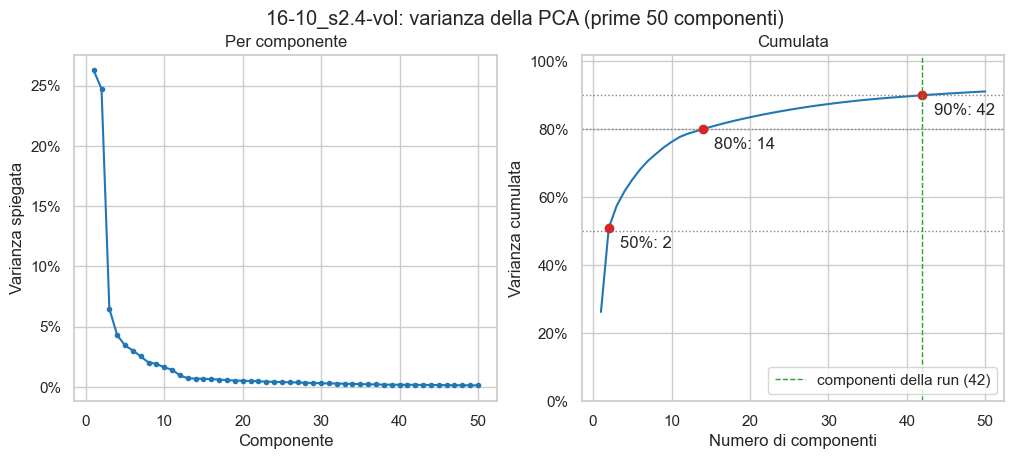

In [4]:
THRESHOLDS = (0.5, 0.8, 0.9)
N_SHOWN = 50

ratio = run.eigenvalues / run.eigenvalues.sum()
cumulative = np.cumsum(ratio)
n_for_share = {share: components_for_share(run.eigenvalues, share) for share in THRESHOLDS}

for share, n_components in n_for_share.items():
    print(f"Per spiegare almeno il {share:.0%} della varianza servono {n_components} componenti")
print(f"La run ne tiene {run.n_components}: {cumulative[run.n_components - 1]:.1%} della varianza")
print()
for k in range(10):
    print(f"Componente {k + 1}: {ratio[k]:.1%} della varianza, {cumulative[k]:.1%} con le componenti fino a questa")

x = np.arange(1, N_SHOWN + 1)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_left.plot(x, ratio[:N_SHOWN], "o-", color="tab:blue", markersize=3)
ax_left.set_xlabel("Componente")
ax_left.set_ylabel("Varianza spiegata")
ax_left.set_title("Per componente")
ax_left.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax_right.plot(x, cumulative[:N_SHOWN], color="tab:blue")
for share, n_components in n_for_share.items():
    ax_right.axhline(share, color="grey", linestyle=":", linewidth=1)
    if n_components <= N_SHOWN:
        ax_right.plot([n_components], [cumulative[n_components - 1]], "o", color="tab:red")
        ax_right.annotate(f"{share:.0%}: {n_components}", (n_components, cumulative[n_components - 1]),
                          textcoords="offset points", xytext=(8, -14))
if run.n_components <= N_SHOWN:
    ax_right.axvline(run.n_components, color="tab:green", linestyle="--", linewidth=1, label=f"componenti della run ({run.n_components})")
    ax_right.legend(loc="lower right")
ax_right.set_xlabel("Numero di componenti")
ax_right.set_ylabel("Varianza cumulata")
ax_right.set_title("Cumulata")
ax_right.set_ylim(0, 1.02)
ax_right.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.suptitle(f"{run.run_dir.name}: varianza della PCA (prime {N_SHOWN} componenti)")
plt.show()

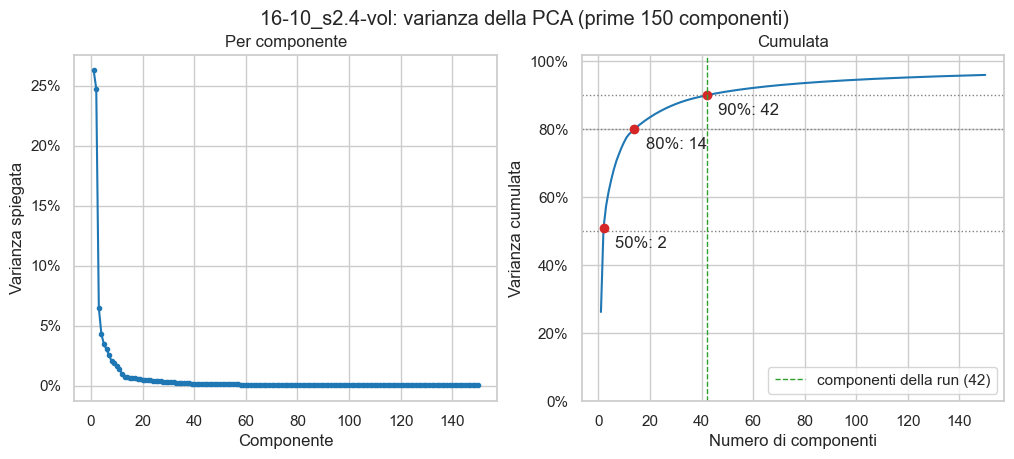

In [5]:
THRESHOLDS = (0.5, 0.8, 0.9)
N_SHOWN = 150

ratio = run.eigenvalues / run.eigenvalues.sum()
cumulative = np.cumsum(ratio)
n_for_share = {share: components_for_share(run.eigenvalues, share) for share in THRESHOLDS}

x = np.arange(1, N_SHOWN + 1)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_left.plot(x, ratio[:N_SHOWN], "o-", color="tab:blue", markersize=3)
ax_left.set_xlabel("Componente")
ax_left.set_ylabel("Varianza spiegata")
ax_left.set_title("Per componente")
ax_left.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax_right.plot(x, cumulative[:N_SHOWN], color="tab:blue")
for share, n_components in n_for_share.items():
    ax_right.axhline(share, color="grey", linestyle=":", linewidth=1)
    if n_components <= N_SHOWN:
        ax_right.plot([n_components], [cumulative[n_components - 1]], "o", color="tab:red")
        ax_right.annotate(f"{share:.0%}: {n_components}", (n_components, cumulative[n_components - 1]),
                          textcoords="offset points", xytext=(8, -14))
if run.n_components <= N_SHOWN:
    ax_right.axvline(run.n_components, color="tab:green", linestyle="--", linewidth=1, label=f"componenti della run ({run.n_components})")
    ax_right.legend(loc="lower right")
ax_right.set_xlabel("Numero di componenti")
ax_right.set_ylabel("Varianza cumulata")
ax_right.set_title("Cumulata")
ax_right.set_ylim(0, 1.02)
ax_right.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.suptitle(f"{run.run_dir.name}: varianza della PCA (prime {N_SHOWN} componenti)")
plt.show()


## 4. Varimax: varianza di ogni componente ruotata

Il varimax ruota le prime *k* componenti: la varianza totale non cambia, ma si ridistribuisce tra loro, e le componenti non hanno più l'ordine di prima. I punteggi hanno tutti varianza 1, quindi non servono per ordinarle.

Qui si calcola quanta varianza spiega ogni componente ruotata: la somma dei pesi al quadrato della sua colonna, divisa per la varianza totale. I pesi si ricavano dai punteggi e dalla matrice di partenza, con una passata a blocchi sulla matrice.

**Come si legge la tabella.** Ogni riga è un posto nella graduatoria per varianza. A sinistra la componente PCA, a destra la componente ruotata che lo occupa (*n.* è la sua etichetta nelle sezioni seguenti).

In [6]:
rotated_share = None
if run.rotation == "none":
    print("La run non è ruotata: questa sezione non si applica.")
else:
    X = load_source_matrix(run)
    rotated_share = rotated_variance_shares(X, run.scores, run.eigenvalues, run.standardize)
    by_variance = np.argsort(rotated_share)[::-1]

    print(f"Varianza spiegata dalle {run.n_components} componenti: {rotated_share.sum():.1%} dopo la rotazione, "
          f"{cumulative[run.n_components - 1]:.1%} prima (il totale non cambia, cambia come è ripartita)")
    print()
    print(f"{'Posto':>6} | {'PCA':>8} | Componente ruotata")
    for place, index in enumerate(by_variance[:10], start=1):
        print(f"{place:>5}º | {ratio[place - 1]:>8.1%} | n. {index + 1:>2}, {rotated_share[index]:.1%}")

Varianza spiegata dalle 42 componenti: 90.1% dopo la rotazione, 90.1% prima (il totale non cambia, cambia come è ripartita)

 Posto |      PCA | Componente ruotata
    1º |    26.3% | n.  1, 20.2%
    2º |    24.7% | n.  2, 12.7%
    3º |     6.5% | n. 19, 10.6%
    4º |     4.3% | n.  8, 5.0%
    5º |     3.4% | n. 27, 4.4%
    6º |     3.0% | n.  6, 3.5%
    7º |     2.5% | n.  7, 3.2%
    8º |     2.0% | n. 30, 3.0%
    9º |     1.9% | n.  3, 3.0%
   10º |     1.6% | n. 21, 2.0%


## 5. Quanto ogni componente dipende dal volume della lesione

**Domanda.** Una componente descrive una zona, o soltanto quanto è grande la lesione?

**R²** è la quota della variabilità del punteggio spiegata dal volume (il quadrato della correlazione).

- R² = 0.04: componente quasi indipendente dalla dimensione.

- R² = 0.50: componente che misura soprattutto la dimensione.

Per un clustering, una componente con R² alto pesa come "dimensione della lesione" anche se spiega molta varianza.

Se c'è un confronto senza rotazione, il grafico mostra entrambe.

In [ ]:
volume = registry_values(run.subject_ids, LESION_VOLUME_COLUMN)
runs_to_compare = {f"rotazione: {run.rotation}": run}
if comparison is not None:
    runs_to_compare["rotazione: none"] = comparison
r2_by_run = {name: squared_correlation(r.scores, volume) for name, r in runs_to_compare.items()}

print(f"Volume della lesione ({LESION_VOLUME_COLUMN}): mediana {np.median(volume):.0f} voxel, da {volume.min():.0f} a {volume.max():.0f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(r2_by_run)
for i, (name, r2) in enumerate(r2_by_run.items()):
    ax.bar(np.arange(1, len(r2) + 1) + (i - (len(r2_by_run) - 1) / 2) * width, r2, width=width, label=name)
ax.axhline(0.1, color="tab:red", linestyle="--", linewidth=1, label="soglia 0.1")
ax.set_xlabel("Componente")
n_components = len(next(iter(r2_by_run.values())))
ax.set_xticks(np.arange(1, n_components + 1))
ax.tick_params(axis="x", labelsize=7)
ax.set_ylabel("R² con il volume della lesione")
ax.set_title(f"{run.run_dir.name}: dipendenza dal volume della lesione")
ax.legend()
plt.show()

### E dal lato della lesione?

**Domanda.** Una componente separa le lesioni di sinistra da quelle di destra?

Il lato si codifica come un numero (1 per la lesione sinistra, 0 per la destra) e si calcola l'**R²** con il punteggio di ogni componente, come per il volume. Dice quanto la componente separa i due lati, non da che parte: il segno di una componente è arbitrario.

Restano fuori i soggetti con lesione bilaterale o senza lato registrato. Il loro numero è stampato qui sotto.

In [ ]:
side, keep = registry_side_indicator(run.subject_ids)
print(f"Soggetti con un solo lato: {int(keep.sum())} su {len(keep)} (sinistra {int(side.sum())}, destra {int((1 - side).sum())})")

r2_side_by_run = {name: squared_correlation(r.scores[keep], side) for name, r in runs_to_compare.items()}

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(r2_side_by_run)
for i, (name, r2) in enumerate(r2_side_by_run.items()):
    ax.bar(np.arange(1, len(r2) + 1) + (i - (len(r2_side_by_run) - 1) / 2) * width, r2, width=width, label=name)
ax.axhline(0.1, color="tab:red", linestyle="--", linewidth=1, label="soglia 0.1")
ax.set_xlabel("Componente")
ax.set_xticks(np.arange(1, len(r2) + 1))
ax.tick_params(axis="x", labelsize=7)
ax.set_ylabel("R² con il lato della lesione")
ax.set_title(f"{run.run_dir.name}: dipendenza dal lato della lesione")
ax.legend()
plt.show()

### Quante componenti servono

Le componenti si prendono in ordine di varianza: per **None** le prime *k*, per **varimax** le *k* con più varianza dopo la rotazione (sezione 4).

Ogni numero è un **R²**: la quota di variabilità del volume (o del lato) spiegata *insieme* dalle prime *k* componenti.

**Come si legge.** Se l'R² sale molto già con *k* piccolo, l'effetto sta nelle prime componenti; se sale piano, è distribuito su molte. A parità di *k*, None e varimax usano insiemi diversi di componenti.

In [ ]:
K_SHOWN = (1, 2, 3, 5, 7, 9, 15, 30)


def cumulative_r2(scores, target, order):
    """R² della regressione lineare di `target` sulle prime k colonne di `scores` (nell'ordine `order`), per ogni k."""
    centered = scores[:, order] - scores[:, order].mean(axis=0)
    q, _ = np.linalg.qr(centered)
    residual_target = target - target.mean()
    return np.cumsum((q.T @ residual_target) ** 2) / (residual_target @ residual_target)


cumulative_by_column = {}
for r in sorted(runs_to_compare.values(), key=lambda r: r.rotation != "none"):
    order = np.arange(r.n_components) if r.rotation == "none" else np.argsort(rotated_share)[::-1]
    label = "None" if r.rotation == "none" else r.rotation.capitalize()
    cumulative_by_column[f"{label} volume"] = cumulative_r2(r.scores, volume, order)
    cumulative_by_column[f"{label} lato"] = cumulative_r2(r.scores[keep], side, order)

ks = [k for k in K_SHOWN if k < run.n_components] + [run.n_components]
print("R² con il volume e con il lato della lesione, usando le prime k componenti (in ordine di varianza)")
print(pd.DataFrame({col: r2[np.array(ks) - 1] for col, r2 in cumulative_by_column.items()},
                   index=pd.Index(ks, name="k")).round(2).to_string())

## 6. Mappe delle componenti nel cervello

**Come si fa.** Per ogni voxel, una regressione mette in relazione la sua disconnessione nei soggetti con i punteggi di tutte le componenti insieme, e dice di quanto cambia quando sale il punteggio di ciascuna. Quel cambiamento, diviso per la sua incertezza, è il *t* del voxel. I *t* di tutti i voxel sul cervello formano la mappa della componente.

È simile alla mappa dei pesi, ma tiene conto dell'incertezza di ogni voxel. Non c'è test di permutazione.

**Riproducibilità.** Si dividono i soggetti in due metà a caso, si rifà la regressione in ciascuna e si correlano (Pearson, sui voxel) le due mappe di ogni componente. 1 = uguali, 0 = niente in comune. I punteggi sono quelli di tutti i soggetti: si verifica che la mappa si ritrovi, non che la PCA sia stabile.

**Come si leggono le figure.**

| Cosa vedi | Significa |
|---|---|
| **Rosso** (*t* positivo) | più il soggetto ha questa componente, più quel voxel è disconnesso |
| **Blu** (*t* negativo) | più il soggetto ha questa componente, meno quel voxel è disconnesso |
| **Colore forte** (*t* alto in valore assoluto) | effetto solido |
| **Colore assente** | effetto sotto la soglia, o nessun effetto |

- **Cosa si cerca.** Dove sta la zona rossa. Se è compatta, la componente è una zona del cervello.

- **Segno.** È arbitrario: ogni mappa è orientata con il picco rosso, quindi si guarda la forma e non il colore.

- **Soglia.** Si colorano i voxel con |*t*| almeno una frazione del picco di quella componente: una soglia fissa, come |*t*| > 3, colorerebbe quasi tutto il cervello. Il picco è nel titolo di ogni figura.

Solo una matrice voxelwise ha una mappa: su una parcellata la sezione salta. La prima volta le mappe si calcolano in background e richiedono qualche minuto; poi restano in cache.

I valori da modificare:

- `COMPONENTS_TO_PLOT`: le componenti da disegnare, da 1 al numero di componenti della run. Esempio: `[1, 2, 3, 4]`.

- `MAP_THRESHOLD_FRACTION`: la quota del picco sotto cui un voxel non è colorato (`0.3` = almeno il 30%).

In [9]:
COMPONENTS_TO_PLOT = [1, 2, 3, 4]
MAP_THRESHOLD_FRACTION = 0.3
MAP_CACHE_DIR = Path("results/cache/component_maps")

if not 0.0 <= MAP_THRESHOLD_FRACTION < 1.0:
    raise ValueError(f"MAP_THRESHOLD_FRACTION deve stare tra 0 e 1 (1 escluso), trovato {MAP_THRESHOLD_FRACTION}")
bad = [k for k in COMPONENTS_TO_PLOT if not 1 <= k <= run.n_components]
if bad or len(set(COMPONENTS_TO_PLOT)) != len(COMPONENTS_TO_PLOT):
    raise ValueError(f"COMPONENTS_TO_PLOT deve avere numeri distinti tra 1 e {run.n_components}, trovato {COMPONENTS_TO_PLOT}")

maps = None
if not (run.source_dir / "non_constant_mask.npy").is_file():
    print("La matrice di partenza non è voxelwise: le mappe nel cervello non si applicano.")
else:
    geometry = load_map_geometry(run.source_dir)
    store = ComponentMapStore(MAP_CACHE_DIR)
    maps = store.request(run.source_dir, run.scores, run.subject_ids)
    if maps is None:
        print("Mappe in calcolo in background (qualche minuto la prima volta)...")
        while maps is None:
            time.sleep(5)
            maps = store.request(run.source_dir, run.scores, run.subject_ids)
    reproducibility = maps.reproducibility
    print(f"Voxel senza varianza residua (t messo a 0): {maps.n_degenerate_voxels}")
    print(f"Riproducibilità tra le due metà, media {reproducibility.mean():.3f} ± {reproducibility.std(ddof=1):.3f}")
    print(f"Da {reproducibility.min():.3f} (componente {reproducibility.argmin() + 1}) a {reproducibility.max():.3f} (componente {reproducibility.argmax() + 1})")
    print()
    for k in range(run.n_components):
        print(f"Componente {k + 1}: riproducibilità = {reproducibility[k]:.3f}, t massimo = {np.abs(maps.t[k]).max():.0f}")

Voxel senza varianza residua (t messo a 0): 0
Riproducibilità tra le due metà, media 0.989 ± 0.006
Da 0.974 (componente 41) a 0.998 (componente 2)

Componente 1: riproducibilità = 0.997, t massimo = 418
Componente 2: riproducibilità = 0.998, t massimo = 329
Componente 3: riproducibilità = 0.996, t massimo = 254
Componente 4: riproducibilità = 0.992, t massimo = 195
Componente 5: riproducibilità = 0.995, t massimo = 244
Componente 6: riproducibilità = 0.997, t massimo = 305
Componente 7: riproducibilità = 0.995, t massimo = 265
Componente 8: riproducibilità = 0.996, t massimo = 300
Componente 9: riproducibilità = 0.994, t massimo = 294
Componente 10: riproducibilità = 0.991, t massimo = 124
Componente 11: riproducibilità = 0.990, t massimo = 132
Componente 12: riproducibilità = 0.982, t massimo = 100
Componente 13: riproducibilità = 0.994, t massimo = 233
Componente 14: riproducibilità = 0.993, t massimo = 127
Componente 15: riproducibilità = 0.991, t massimo = 138
Componente 16: riprod

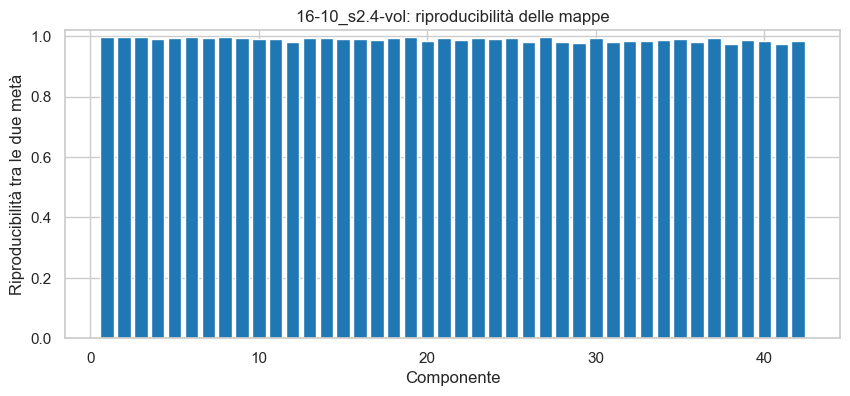

In [10]:
if maps is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(np.arange(1, run.n_components + 1), reproducibility, color="tab:blue")
    ax.set_xlabel("Componente")
    ax.set_ylabel("Riproducibilità tra le due metà")
    ax.set_title(f"{run.run_dir.name}: riproducibilità delle mappe")
    ax.set_ylim(0, 1.02)
    plt.show()

### Le mappe

Una figura per componente, con le sezioni sagittale, coronale e assiale sul picco di *t*. Rosso positivo, blu negativo. Sfondo: template MNI T1 a 1 mm.

/opt/anaconda3/envs/nemesis/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2625: RuntimeWarning: invalid value encountered in <lambda> (vectorized)
  outputs = ufunc(*args, out=...)


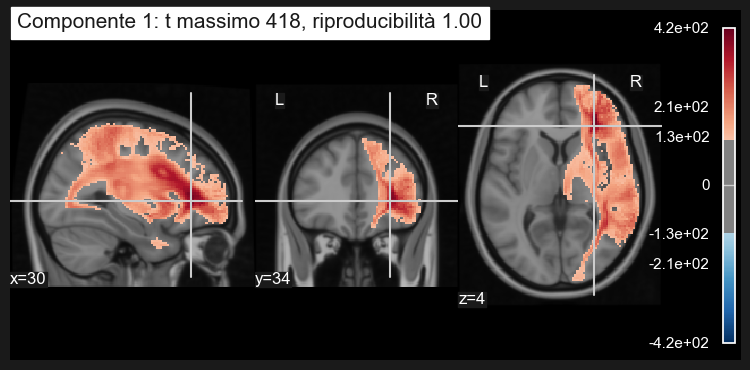

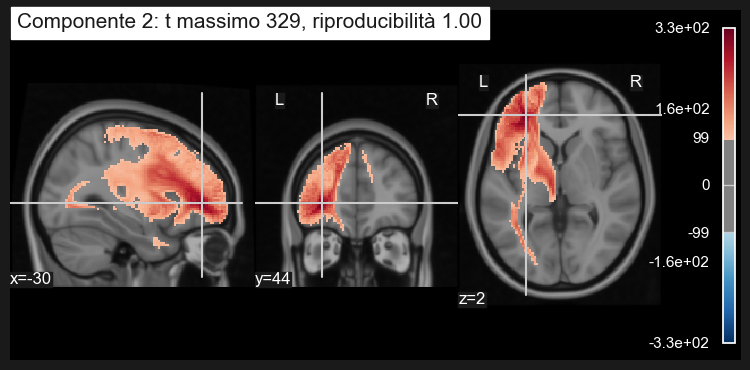

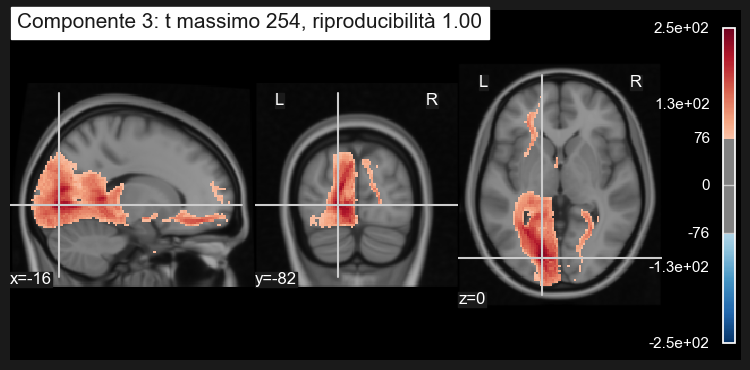

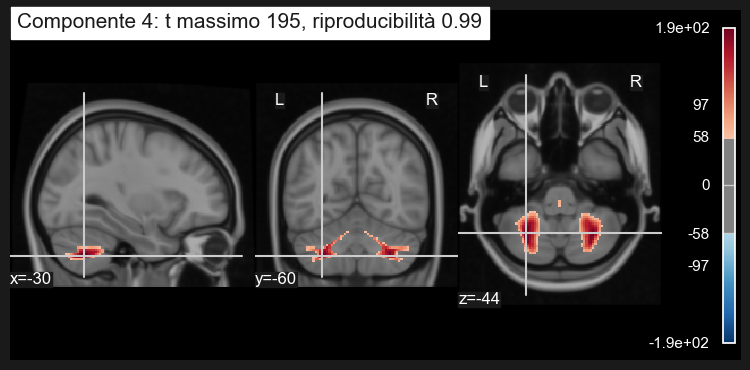

In [11]:
if maps is not None:
    background = nib.load("assets/templates/tpl-MNI152NLin6Asym_res-1_T1w.nii.gz")
    voxel_columns = np.flatnonzero(geometry.mask)
    for k in COMPONENTS_TO_PLOT:
        t_map = np.asarray(maps.t[k - 1])
        peak_column = int(np.argmax(np.abs(t_map)))
        peak_mm = nib.affines.apply_affine(geometry.affine, np.unravel_index(voxel_columns[peak_column], geometry.shape))
        plotting.plot_stat_map(
            to_volume(t_map, geometry),
            bg_img=background,
            threshold=MAP_THRESHOLD_FRACTION * abs(t_map[peak_column]),
            cut_coords=tuple(peak_mm),
            display_mode="ortho",
            title=f"Componente {k}: t massimo {t_map[peak_column]:.0f}, riproducibilità {reproducibility[k - 1]:.2f}",
        )
        plt.show()

## 7. Embedding

Un punto per soggetto, nelle due componenti scelte, colorato per lato della lesione, volume e dataset. Serve a vedere se le componenti separano i soggetti per qualcosa che si conosce.

- **Senza rotazione**, le prime due componenti sono le direzioni che separano di più i soggetti.

- **Con il varimax**, le colonne non hanno ordine: di default si disegnano le due componenti che spiegano più varianza (sezione 4).

Il grigio è un valore non disponibile.

Il valore da modificare:

- `EMBEDDING_COMPONENTS`: le due componenti da disegnare, numerate da 1, per esempio `(1, 3)`. Con `None` si scelgono da sole.

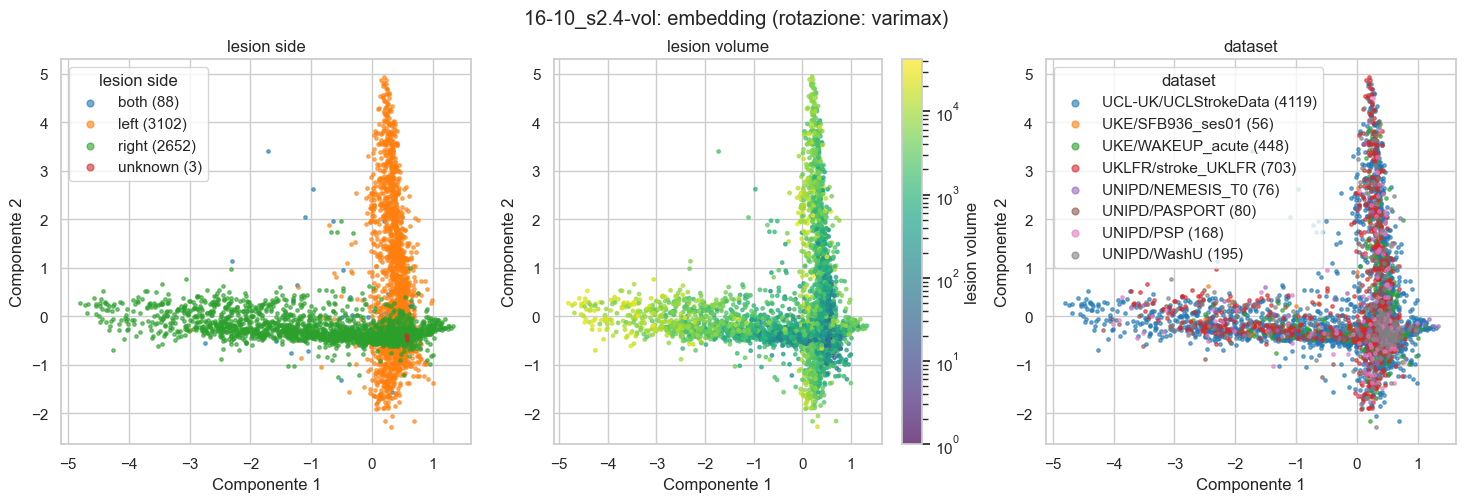

In [12]:
EMBEDDING_COMPONENTS = None
COLOR_MODES_TO_SHOW = ["side", "volume", "dataset"]

if EMBEDDING_COMPONENTS is None:
    first, second = default_embedding_components(run.rotation, rotated_share)
else:
    first, second = (k - 1 for k in EMBEDDING_COMPONENTS)
for k in (first, second):
    if not 0 <= k < run.n_components:
        raise ValueError(f"le componenti vanno da 1 a {run.n_components}, trovata {k + 1}")
points = run.scores[:, [first, second]]

fig, axes = plt.subplots(1, len(COLOR_MODES_TO_SHOW), figsize=(6 * len(COLOR_MODES_TO_SHOW), 5))
for ax, mode_name in zip(np.atleast_1d(axes), COLOR_MODES_TO_SHOW):
    mode = resolve_color_mode(mode_name)
    values = color_values(metadata, mode_name)
    if mode.kind == "categorical":
        categories = [c for c in (mode.categories or sorted(set(values))) if c in set(values)]
        palette = dict(zip(categories, sns.color_palette("tab10", len(categories))))
        for category in categories:
            chosen = values == category
            ax.scatter(*points[chosen].T, s=6, alpha=0.6, color=palette[category], label=f"{category} ({chosen.sum()})")
        ax.legend(title=mode.label, loc="best", markerscale=2)
    else:
        numeric = values.astype(float)
        known = ~np.isnan(numeric)
        ax.scatter(*points[~known].T, s=6, color="lightgrey")
        scatter = ax.scatter(*points[known].T, s=6, alpha=0.7, c=numeric[known], cmap="viridis",
                             norm=LogNorm() if mode.log_scale else None)
        fig.colorbar(scatter, ax=ax, label=mode.label)
    ax.set_xlabel(f"Componente {first + 1}")
    ax.set_ylabel(f"Componente {second + 1}")
    ax.set_title(mode.label)
fig.suptitle(f"{run.run_dir.name}: embedding (rotazione: {run.rotation})")
plt.show()